# 02 · Manifold — principal-curve trajectory

Xing's malignant manifold is **non-branching**: a single continuous developmental gradient, not a hub
radiating into discrete subtypes. Across a curve-parameter scan (Nodes 15/20/30 × λ 0.3/1.0) ElPiGraph
returns **2 tips, 0 forks** with a fold self-approach ratio > 2.3 every time — a robustly linear
topology, so the correct model is a **principal curve** (non-branching by construction) fit on the
*joint* embedding (no re-embedding: rotating to house orientation is distance-preserving). The curve is
rooted at the gastrulation/somitogenesis-high tip (the developmental origin), pseudotime flows to the
neural-crest terminus, and the fitted curve is rendered over the cells to confirm it does not fold back.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the processed manifold (whole developmental continuum)

We keep the cells on their *original joint embedding coordinates* — no re-embedding — and fit the curve
on the whole manifold (§01 established there is no discrete sub-compartment to scope to).

manifold cells: 8920 on the joint embedding
UMAP aspect ratio (major/minor std): 1.30


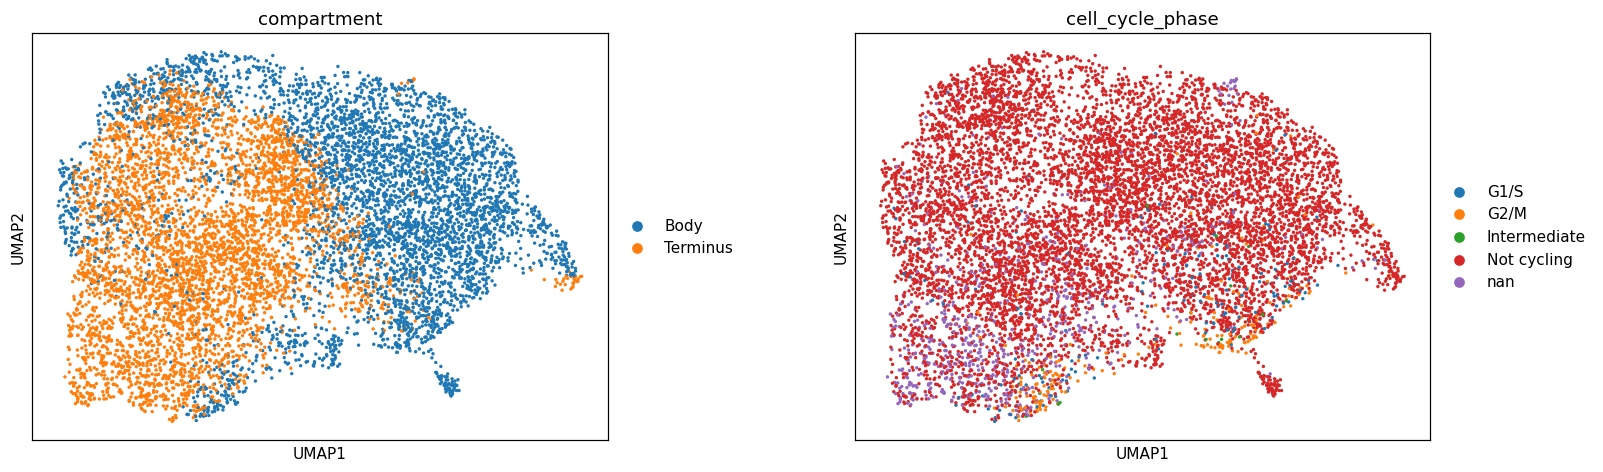

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('manifold cells:', adata.shape[0], 'on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print('UMAP aspect ratio (major/minor std): %.2f' % (s[0]/s[1]))
fig = sc.pl.umap(adata, color=['compartment','cell_cycle_phase'], size=20, wspace=.3, show=False)
plt.show()

### Curve-parameter scan → fold-free non-branching topology

`fold_diag` reports the graph tips/forks and a **self-approach ratio** — the minimum distance between
graph-non-adjacent nodes in units of median edge length; a value > 1 certifies the curve does not fold
back on itself. Every parameter combination gives 0 forks and a comfortable margin, so we commit to
**Nodes=20, λ=0.3, μ=100** (`epg_mu=100` is strong bending regularisation, keeping the backbone a
smooth arc rather than a sharp V that would assign near-neighbour cells divergent pseudotime).

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks

print('curve-parameter scan (self-approach >1 = fold-free):')
for Nodes in [15,20,30]:
    for lam in [0.3,1.0]:
        ad = adata.copy()
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.curve(ad, Nodes=Nodes, use_rep='X_umap', epg_lambda=lam, epg_mu=100.0, seed=SEED, plot=False)
        sa,tips,forks = fold_diag(ad)
        print('  Nodes=%2d lambda=%.1f mu=100: tips=%d forks=%d self-approach=%.2f' % (Nodes,lam,tips,forks,sa))
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(adata)
print('committed curve: Nodes=20 lambda=0.3 mu=100 -> tips=%d forks=%d self-approach=%.2f' % (tips,forks,sa))
assert forks == 0 and sa > 1, 'topology check failed'

curve-parameter scan (self-approach >1 = fold-free):
  Nodes=15 lambda=0.3 mu=100: tips=2 forks=0 self-approach=2.95
  Nodes=15 lambda=1.0 mu=100: tips=2 forks=0 self-approach=2.96
  Nodes=20 lambda=0.3 mu=100: tips=2 forks=0 self-approach=2.74
  Nodes=20 lambda=1.0 mu=100: tips=2 forks=0 self-approach=2.85
  Nodes=30 lambda=0.3 mu=100: tips=2 forks=0 self-approach=2.31
  Nodes=30 lambda=1.0 mu=100: tips=2 forks=0 self-approach=2.62
committed curve: Nodes=20 lambda=0.3 mu=100 -> tips=2 forks=0 self-approach=2.74


### Branching test — is there a stable fork? (shown, not asserted)

`scf.tl.curve` is non-branching *by construction*, so it cannot by itself rule out a bifurcation. We
therefore fit a branching-capable **PPT tree** across a parameter grid and count forks: a genuine
single bifurcation gives ~1 stable fork (3 tips) robustly across parameters, whereas a roundish
continuous cloud yields a fork count that **grows with node density** (the tree fits noise). Here forks
scale from 2 to 15 as Nodes increase — no stable bifurcation — confirming the **non-branching** read off
the embedding (one continuous roundish mass, aspect ~1.3, no hub-and-spoke).

In [5]:
import scFates as scf2
print('PPT tree fork counts across the parameter grid (branching-capable fit):')
for Nodes in [30,50,100,200]:
    a = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a, method='ppt', Nodes=Nodes, ppt_lambda=2000, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(a.uns['graph']['B']); deg = (B>0).sum(0)
    print('  Nodes=%3d lambda=2000 sigma=0.5: tips=%d forks=%d' % (Nodes, int((deg==1).sum()), int((deg>=3).sum())))
print('fork count grows with node density -> no stable single bifurcation -> non-branching (fit a curve)')
# restore the committed non-branching curve for the downstream root/pseudotime
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(adata)
print('committed curve restored: tips=%d forks=%d self-approach=%.2f' % (tips,forks,sa))

PPT tree fork counts across the parameter grid (branching-capable fit):
  Nodes= 30 lambda=2000 sigma=0.5: tips=4 forks=2
  Nodes= 50 lambda=2000 sigma=0.5: tips=6 forks=4
  Nodes=100 lambda=2000 sigma=0.5: tips=7 forks=5
  Nodes=200 lambda=2000 sigma=0.5: tips=7 forks=5
fork count grows with node density -> no stable single bifurcation -> non-branching (fit a curve)
committed curve restored: tips=2 forks=0 self-approach=2.74


### Derive the root (data-driven) and infer pseudotime

The three developmental signatures were scored and graph-smoothed in §01. The root is set to the curve
tip where Gast+pSom is highest and Crest lowest — the developmental origin. Pseudotime then flows toward
the neural-crest terminus; the Spearman gradients confirm Gast and pSom **decline** while Crest **rises**.

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (t, info[t][0], info[t][1], info[t][2]))
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip %d (Gast/pSom-high, Crest-low)' % root)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print('  %s: rho=%+.3f p=%.1e' % (s, rho, p))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())

tip 0: Gast=-0.0226 pSom=+0.0422 Crest=-0.0163
tip 2: Gast=-0.0117 pSom=+0.0548 Crest=-0.0327
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.397 p=0.0e+00
  pSom_sm: rho=-0.267 p=4.1e-145
  Crest_sm: rho=+0.690 p=0.0e+00
Crest-high decile mean pseudotime = 0.92 (terminal if ~1)


### House orientation (verified against pseudotime)

The house orientation (rigid rotation of the developmental axis to horizontal, origin on the left) was
fixed in §01 as `X_umap_lin`. Here we only **verify** it agrees with the independently-computed
pseudotime (positive correlation, low pseudotime on the left).

In [7]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
c = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_,_,vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0, 'stored orientation not pseudotime-consistent (corr=%.2f)' % r
print('house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = %+.2f' % r)
print('variance-axis vs pseudotime-axis disagreement = %.1fdeg (small -> equivalent orientation)' % dang)

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.94
variance-axis vs pseudotime-axis disagreement = 2.8deg (small -> equivalent orientation)


### Fold check — render the fitted curve over the cells

The self-approach ratio already certifies a fold-free backbone; we also **draw the fitted curve** on the
house orientation (a metric read off the embedding can be blind to a fold, so the render is the
independent check). A single smooth arc from root to terminus confirms the topology.

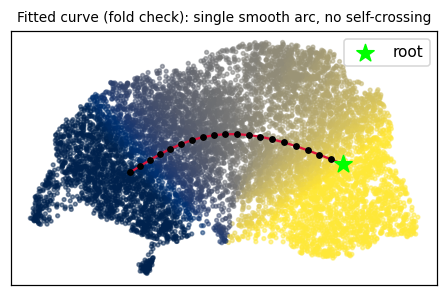

In [8]:
F = adata.uns['graph']['F'].T                       # nodes in raw X_umap space
cc = adata.obsm['X_umap'].mean(0)
_,_,vt = np.linalg.svd(adata.obsm['X_umap']-cc, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
Fl = (F-cc) @ Rm.T
# match the sign flip applied to X_umap_lin in 01 (origin on left)
if np.corrcoef(((adata.obsm['X_umap']-cc)@Rm.T)[:,0], t)[0,1] > 0 and np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1] > 0:
    same = np.allclose(((adata.obsm['X_umap']-cc)@Rm.T)[:,0], adata.obsm['X_umap_lin'][:,0], atol=1e-6)
    if not same: Fl[:,0] = -Fl[:,0]
Bm = np.asarray(adata.uns['graph']['B']); xl = adata.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(5,3))
ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=6, alpha=.5)
ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj): ax.plot([Fl[a,0],Fl[b,0]],[Fl[a,1],Fl[b,1]], '-', color='crimson', lw=1.5, zorder=5)
ax.scatter(Fl[:,0], Fl[:,1], c='black', s=12, zorder=6)
ax.scatter(Fl[root,0], Fl[root,1], c='lime', s=140, marker='*', zorder=7, label='root')
ax.set_title('Fitted curve (fold check): single smooth arc, no self-crossing', size=9)
ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.show()

### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


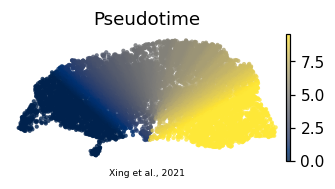

In [9]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Xing et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')
plt.show()